# Customer segmentation (Q3: which customer groups should marketing target?)

Two approaches: a rule-based **RFM segmentation** that marketing can act on directly, and **K-Means clustering** to check whether the data suggests different groups.

RFM scores each customer on **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** value (total spend). Because 96.9% of customers ordered only once, frequency is used as a simple flag (repeat customer or not) instead of the usual quintile score.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

con = duckdb.connect("../warehouse/olist.duckdb", read_only=True)
q = lambda sql: con.sql(sql).df()
FIG = "../reports/figures/"

cust = q("""
    SELECT customer_unique_id,
           date_diff('day', CAST(last_order_at AS DATE),
                     (SELECT max(purchase_date) FROM marts.fct_orders) + 1) AS recency_days,
           n_orders               AS frequency,
           lifetime_value::DOUBLE AS monetary,
           avg_review_score
    FROM marts.dim_customers
    WHERE n_orders > 0
""")

print(len(cust), "customers")
cust.describe().round(1)

94990 customers


,recency_days,frequency,monetary,avg_review_score
count,94990.0,94990.0,94990.0,94305.0
mean,288.3,1.0,165.7,4.1
std,153.0,0.2,226.7,1.3
min,2.0,1.0,0.0,1.0
25%,164.0,1.0,63.1,4.0
50%,269.0,1.0,107.9,5.0
75%,397.0,1.0,182.9,5.0
max,774.0,16.0,13664.1,5.0


In [2]:
# R and M as quintile scores, 5 = best. rank(method="first") breaks ties so qcut always finds 5 bins.
cust["R"] = pd.qcut(cust["recency_days"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
cust["M"] = pd.qcut(cust["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["is_repeat"] = cust["frequency"] > 1

# Rules are checked top to bottom; the first match wins
conditions = [
    cust["is_repeat"] & (cust["R"] >= 4),
    cust["is_repeat"],
    (cust["R"] >= 4) & (cust["M"] >= 4),
    cust["R"] >= 4,
    (cust["R"] <= 2) & (cust["M"] >= 4),
    cust["R"] <= 2,
]
choices = ["Champions", "Loyal, lapsing", "New, high value", "New, low value",
           "Lost, high value", "Hibernating"]
cust["segment"] = np.select(conditions, choices, default="Needs attention")

summary = (
    cust.groupby("segment")
        .agg(customers=("customer_unique_id", "count"),
             avg_recency_days=("recency_days", "mean"),
             avg_spend=("monetary", "mean"),
             total_spend=("monetary", "sum"))
        .assign(pct_customers=lambda d: (100 * d["customers"] / d["customers"].sum()).round(1),
                pct_revenue=lambda d: (100 * d["total_spend"] / d["total_spend"].sum()).round(1))
        .sort_values("total_spend", ascending=False)
        .round(1)
)
summary

,customers,avg_recency_days,avg_spend,total_spend,pct_customers,pct_revenue
segment,,,,,,
"New, high value",14641,141.6,303.0,4436448.3,15.4,28.2
"Lost, high value",13999,444.9,309.1,4326439.1,14.7,27.5
Needs attention,18378,270.2,152.1,2795663.8,19.3,17.8
Hibernating,22966,446.2,72.7,1670437.9,24.2,10.6
"New, low value",22118,139.7,73.1,1616279.4,23.3,10.3
"Loyal, lapsing",1651,371.0,298.7,493110.1,1.7,3.1
Champions,1237,138.5,321.1,397148.4,1.3,2.5


## RFM segments and recommended actions

| Segment | Customers | % revenue | Who they are | Recommended action |
| --- | --- | --- | --- | --- |
| New, high value | 14,641 (15.4%) | 28.2% | One recent order, high spend (avg R\$303) | Second-purchase incentive in the same category |
| Lost, high value | 13,999 (14.7%) | 27.5% | One high-spend order (avg R\$309), ~445 days ago | One targeted win-back offer, then stop |
| Needs attention | 18,378 (19.3%) | 17.8% | One order, middling recency and spend | Low-cost reminder email |
| Hibernating | 22,966 (24.2%) | 10.6% | One low-spend order (avg R\$73), long ago | Exclude from paid campaigns |
| New, low value | 22,118 (23.3%) | 10.3% | One recent, low-spend order (avg R\$73) | Cross-sell bundles, free-shipping threshold |
| Loyal, lapsing | 1,651 (1.7%) | 3.1% | Repeat buyers, not seen for ~370 days | Personalised win-back offer |
| Champions | 1,237 (1.3%) | 2.5% | Repeat buyers, ordered recently (avg R\$321) | Early access and referral programme |

**Key findings**
- **Two high-value segments are 30% of customers but 56% of revenue.** Converting "New, high value" customers into repeat buyers is the biggest opportunity, because they are recent and already spend about R\$300.
- **Repeat customers spend nearly twice the average** (R\$300–320 vs R\$166), confirming that retention, not acquisition, is the lever to grow revenue per customer.
- **Nearly half of customers (47.5%) are low-value one-time buyers** (Hibernating and New, low value) who generate about 21% of revenue. They should get low-cost channels only.

,k,inertia,silhouette
0,2,299309.689,0.627
1,3,223879.132,0.356
2,4,168287.794,0.333
3,5,133723.433,0.324
4,6,120972.371,0.298
5,7,111212.266,0.284
6,8,102204.502,0.290


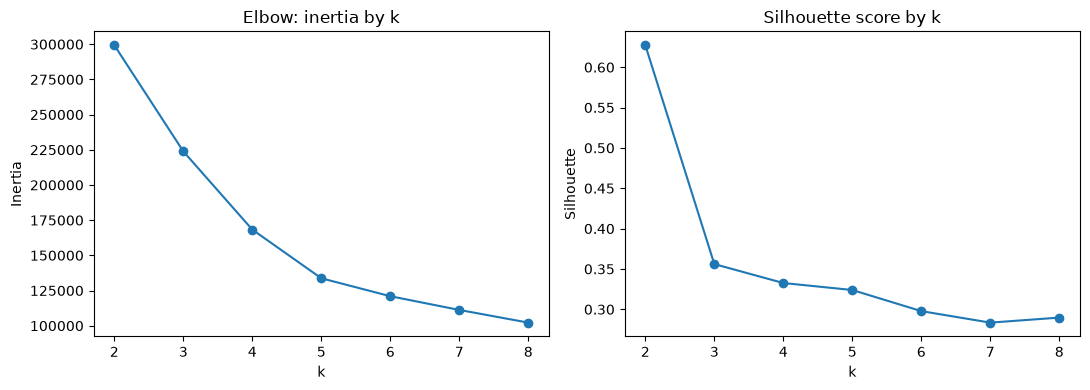

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

features = pd.DataFrame({
    "log_recency":  np.log1p(cust["recency_days"]),
    "log_monetary": np.log1p(cust["monetary"]),
    "frequency":    cust["frequency"],
    "review":       cust["avg_review_score"].fillna(cust["avg_review_score"].median()),
})
X = StandardScaler().fit_transform(features)

rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_, sample_size=10_000, random_state=42)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
scores = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(scores["k"], scores["inertia"], marker="o")
axes[0].set(title="Elbow: inertia by k", xlabel="k", ylabel="Inertia")
axes[1].plot(scores["k"], scores["silhouette"], marker="o")
axes[1].set(title="Silhouette score by k", xlabel="k", ylabel="Silhouette")
fig.tight_layout()
fig.savefig(FIG + "kmeans_choose_k.png", dpi=150)
scores.round(3)

## Choosing k

The silhouette score is highest at k = 2 (0.627), but that split mainly separates repeat buyers from one-time buyers, which Q2 already established and which gives marketing nothing new to act on. The elbow plot flattens after **k = 5** (inertia falls by 34,600 from k = 4 to 5, but only 12,800 from 5 to 6), and the silhouette score barely changes between k = 3 and 5 (0.356 to 0.324). I therefore chose **k = 5**: the most distinct, actionable groups for almost no loss in cluster separation.

In [4]:
k = 5
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
cust["cluster"] = km.labels_

profile = (
    cust.groupby("cluster")
        .agg(customers=("customer_unique_id", "count"),
             avg_recency_days=("recency_days", "mean"),
             avg_orders=("frequency", "mean"),
             avg_spend=("monetary", "mean"),
             avg_review=("avg_review_score", "mean"))
        .assign(pct_customers=lambda d: (100 * d["customers"] / d["customers"].sum()).round(1))
        .round(2)
)
profile

,customers,avg_recency_days,avg_orders,avg_spend,avg_review,pct_customers
cluster,,,,,,
0,23086,344.40,1.00,318.26,4.62,24.3
1,32056,369.97,1.00,67.26,4.59,33.7
2,2888,271.38,2.11,308.26,4.16,3.0
3,14568,288.58,1.00,178.14,1.46,15.3
4,22392,115.57,1.00,122.67,4.64,23.6


In [5]:
pd.crosstab(cust["segment"], cust["cluster"], normalize="columns").round(2)

cluster,0,1,2,3,4
segment,,,,,
Champions,0.00,0.00,0.43,0.00,0.00
Hibernating,0.02,0.60,0.00,0.21,0.00
"Lost, high value",0.51,0.00,0.00,0.16,0.00
"Loyal, lapsing",0.00,0.00,0.57,0.00,0.00
Needs attention,0.25,0.27,0.00,0.27,0.00
"New, high value",0.21,0.00,0.00,0.17,0.32
"New, low value",0.01,0.12,0.00,0.20,0.68


## K-Means clusters (k = 5)

| Cluster | Name | Customers | Avg recency (days) | Avg spend | Avg review | Profile |
| --- | --- | --- | --- | --- | --- | --- |
| 2 | Repeat buyers | 2,888 (3.0%) | 271 | R\$308 | 4.16 | The only cluster with repeat orders (2.11 on average); identical to RFM Champions + Loyal, lapsing |
| 4 | Recent and happy | 22,392 (23.6%) | 116 | R\$123 | 4.64 | Most recent buyers, highly satisfied |
| 0 | Lapsed big spenders | 23,086 (24.3%) | 344 | R\$318 | 4.62 | High spend and satisfied, but long inactive |
| 1 | Low-value lapsed | 32,056 (33.7%) | 370 | R\$67 | 4.59 | Low spend, long inactive |
| 3 | Unhappy customers | 14,568 (15.3%) | 289 | R\$178 | 1.46 | Very low reviews, spread across all RFM segments |

**Comparison with RFM**
- The two methods agree on the main structure: the repeat-buyer cluster matches the RFM repeat segments exactly, and the recency and spend splits line up with the RFM groups.
- **K-Means finds a group RFM cannot see: 14,568 unhappy customers (15.3%) with an average review of 1.46.** They are spread across every RFM segment (16–27% each from five segments), so RFM treats them like happy customers with the same recency and spend. They spend above average (R\$178 vs R\$166), so they are not low-value customers.

**Recommendation:** marketing should **exclude cluster 3 from standard promotional campaigns** (a discount email to someone who just left a 1-star review is likely to backfire) and route them to customer service recovery instead. The Q4 finding that late deliveries drive bad reviews suggests many of these customers had a late order, which motivates the Phase 6 model: catching these customers *before* they leave a bad review.

In [6]:
cluster_names = {0: "Lapsed big spenders", 1: "Low-value lapsed", 2: "Repeat buyers",
                 3: "Unhappy customers", 4: "Recent and happy"}
cust["cluster_name"] = cust["cluster"].map(cluster_names)

cust[["customer_unique_id", "recency_days", "frequency", "monetary",
      "R", "M", "segment", "cluster", "cluster_name"]].to_parquet(
    "../warehouse/customer_segments.parquet", index=False)

cust["cluster_name"].value_counts()

cluster_name
Low-value lapsed       32056
Lapsed big spenders    23086
Recent and happy       22392
Unhappy customers      14568
Repeat buyers           2888
Name: count, dtype: int64